## 1. Load runtime service 

In [5]:
from qiskit_ibm_runtime import QiskitRuntimeService
# for api token 
import keyring as k3

# set the qubit count
n_qubits = 8

# Get the API token from keyring
api_token = k3.get_password('ibm_quantum', 'api_token')


# set up your backend 
service = QiskitRuntimeService(channel="ibm_quantum", token=api_token)
backend = service.least_busy(
    operational=True, 
    simulator=False, 
    min_num_qubits=n_qubits
)

print(f"Using backend: {backend}")
print("Backend Loaded")


Using backend: <IBMBackend('ibm_brisbane')>
Backend Loaded


## 2. Create circuit and tranpile 

Circuit Created


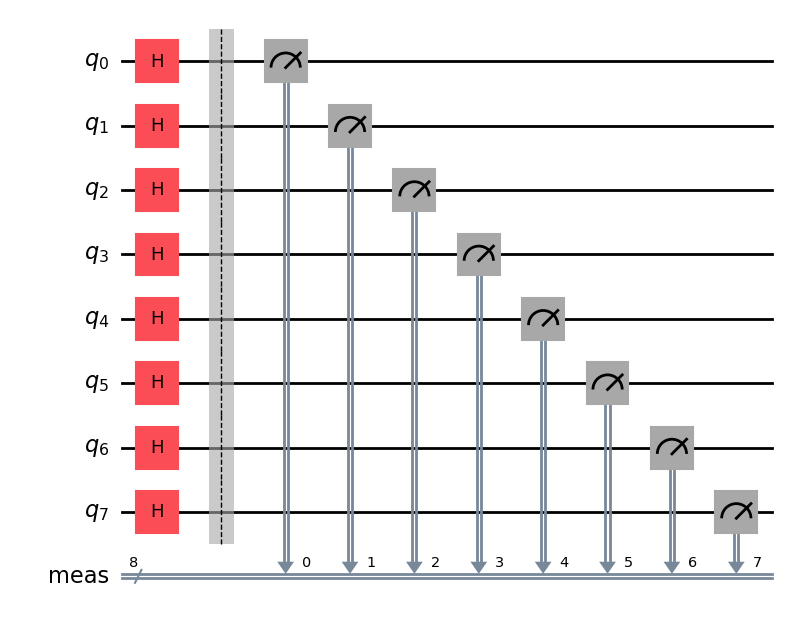

In [6]:
from qiskit import QuantumCircuit, transpile

# create a Bell circuit
qc = QuantumCircuit(n_qubits)
for i in range(n_qubits):
    qc.h(i)

qc.measure_all()

print("Circuit Created")
qc.draw('mpl')


## 2.1 - Optimize the circuit 

Optimized Circuit Created


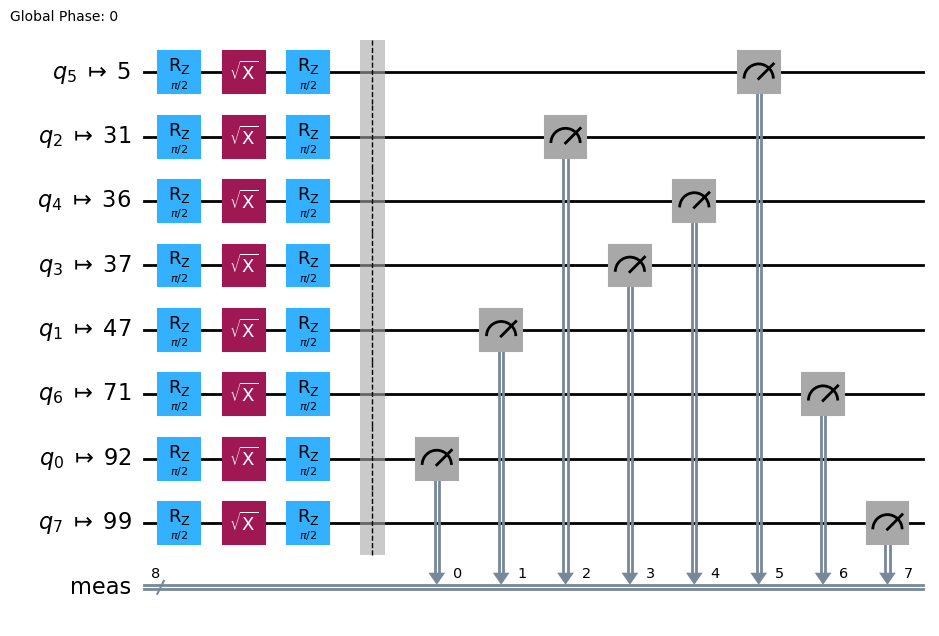

In [7]:
# transpile the circuit
transpiled_circuit = transpile(qc, backend=backend)

#construct  pub 
pub_qc_measurement = (transpiled_circuit) 

print("Optimized Circuit Created")
transpiled_circuit.draw('mpl')


## 3. Initialize a Sampler primitive and run 

In [8]:
from qiskit_ibm_runtime import SamplerV2

# Inaitialize the sampler
sampler = SamplerV2(backend)
job_qc_measurement = sampler.run([pub_qc_measurement], shots=1500)

# Extract results
result_qc_measurement = job_qc_measurement.result()
data_qc_measurement = result_qc_measurement[0].data
print("qc Measurement Results:")
print(data_qc_measurement)





qc Measurement Results:
DataBin(meas=BitArray(<shape=(), num_shots=1500, num_bits=8>))


## 4. Read the data 

In [9]:
bits = data_qc_measurement.meas
print('Shape: ', bits.shape)
print('num bits: ', bits.num_bits)
print('num shots: ', bits.num_shots)
print("array:\n", bits.array)



Shape:  ()
num bits:  8
num shots:  1500
array:
 [[221]
 [223]
 [106]
 ...
 [115]
 [ 49]
 [108]]


In [10]:
bitstrings = bits.get_bitstrings()
print("Bitstrings:", bitstrings)

Bitstrings: ['11011101', '11011111', '01101010', '01010111', '11110101', '00101110', '11011010', '01000101', '00011111', '11001100', '00010100', '01100110', '00101110', '00001111', '10000001', '10101010', '01111010', '10001101', '01010100', '01110101', '01011001', '00100111', '00111100', '01110001', '00110101', '01111111', '10001110', '01010001', '01000000', '11000011', '00111111', '01101100', '11001000', '01100100', '10010101', '01100001', '11100000', '01100111', '01111100', '11110001', '01010011', '10111100', '10110011', '00111111', '10100001', '11011000', '00101000', '01010101', '01100000', '00001101', '00000110', '11100111', '01100110', '01010001', '01101101', '00011000', '11000000', '01111110', '11001011', '01011111', '00010100', '10101001', '10001001', '10010110', '00111111', '11001100', '01101100', '01100010', '00111001', '10111100', '00001010', '11000100', '00101111', '11101010', '11100001', '11010001', '00010001', '00101010', '10110000', '01110000', '01110100', '10111110', '11

In [11]:
len(bitstrings)

1500

In [12]:
import csv
from datetime import datetime

now = datetime.now()
date_time_str = now.strftime("_%Y_%m_%d_%H_%M_%S")
save_path = 'C:\\Users\\patri\\OneDrive\\Projects\\Quantum_IBM\\learning\\data\\data\\' 



def write_strings_to_csv(data, filename):
    """Writes an array of strings to a CSV file.

    Args:
        data: A list of strings.
        filename: The name of the CSV file to write to.
    """
    with open(filename, 'w', newline='') as csvfile:
        writer = csv.writer(csvfile)
        for row in data:
            writer.writerow([row])

# Example usage:
string_array = bitstrings
output_filename = save_path + "random_nums" + date_time_str + ".csv"
write_strings_to_csv(string_array, output_filename)